Анализ RFSD: 1000 строк × 20 колонок

Проект для учебного задания по анализу данных на основе **Russian Financial Statements Database (RFSD)**.

Источник: https://github.com/irlcode/RFSD

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

DATASET = "irlspbru/RFSD"
N_ROWS = 1000
N_COLS = 20
OUT = Path("results")
OUT.mkdir(exist_ok=True)

# Сразу после загрузки сохраняются ровно 20 числовых финансовых показателей
# К ним относятся итоговые показатели и статьи бухгалтерского баланса, а также показатели отчета о прибылях и убытках
COLUMNS = [
    "age", "line_1100", "line_1150", "line_1200", "line_1210", "line_1220",
    "line_1240", "line_1250", "line_1260", "line_1300", "line_1400",
    "line_1500", "line_1600", "line_2100", "line_2110",
    "line_2200", "line_2300", "line_2400", "line_2500", "line_4400"
]

LABELS = {
  "age":      "Возраст предприятия",
  "line_1100": "Внеоборотные активы (1100)",
  "line_1150": "Основные средства (1150)",
  "line_1200": "Оборотные активы (1200)",
  "line_1210": "Запасы (1210)",
  "line_1220": "НДС по приобретенным ценностям (1220)",
  "line_1240": "Дебиторская задолженность (1240)",
  "line_1250": "Финансовые вложения (1250)",
  "line_1260": "Прочие оборотные активы (1260)",
  "line_1300": "Капитал и резервы (1300)",
  "line_1400": "Долгосрочные обязательства (1400)",
  "line_1500": "Краткосрочные обязательства (1500)",
  "line_1600": "Итого по балансу (1600)",
  "line_2100": "Валовая прибыль (2100)",
  "line_2110": "Выручка (2110)",
  "line_2200": "Прибыль от продаж (2200)",
  "line_2300": "Прибыль до налогообложения (2300)",
  "line_2400": "Чистая прибыль (2400)",
  "line_2500": "Результат за период (2500)",
  "line_4400": "Баланс (4400)",
}

Этап 1. Загрузка датасета

In [4]:
"""Берём только 1000 записей вместо загрузки полного датасета"""
stream = load_dataset(DATASET, split="train", streaming=True)
#Проверяем строки на заполненность. Я поставил для отсечения размер в максимум 5
#незаполненных столбцов, чтобы попасть в выборку
def is_complete(row):
    count_of_incompleted_columns=0
    for col in COLUMNS:
        value = row[col]

        if pd.isna(value):
            count_of_incompleted_columns+=1

        if isinstance(value, str) and not value.strip():
            count_of_incompleted_columns+=1

        if count_of_incompleted_columns>=5:
          return False

    return True


rows = []
for row in stream:
    if is_complete(row):
        rows.append(row)
        if len(rows)%10==0:
          print(f'Загружено {len(rows)} строк')

    if len(rows) >= 1000:
        break

df = pd.DataFrame(rows, columns=COLUMNS)

# Берём только 20 столбцов перед статистическим анализом
missing = [c for c in COLUMNS if c not in df.columns]
if missing:
    raise RuntimeError(f"Пропущены столбцы: {missing}")
df = df[COLUMNS].copy()
df = df.apply(pd.to_numeric, errors="coerce")

df.to_csv(OUT / "sample_1000_20cols.csv", index=False)

README.md:   0%|          | 0.00/22.9k [00:00<?, ?B/s]

Загружено 10 строк
Загружено 20 строк
Загружено 30 строк
Загружено 40 строк
Загружено 50 строк
Загружено 60 строк
Загружено 70 строк
Загружено 80 строк
Загружено 90 строк
Загружено 100 строк
Загружено 110 строк
Загружено 120 строк
Загружено 130 строк
Загружено 140 строк
Загружено 150 строк
Загружено 160 строк
Загружено 170 строк
Загружено 180 строк
Загружено 190 строк
Загружено 200 строк
Загружено 210 строк
Загружено 220 строк
Загружено 230 строк
Загружено 240 строк
Загружено 250 строк
Загружено 260 строк
Загружено 270 строк
Загружено 280 строк
Загружено 290 строк
Загружено 300 строк
Загружено 310 строк
Загружено 320 строк
Загружено 330 строк
Загружено 340 строк
Загружено 350 строк
Загружено 360 строк
Загружено 370 строк
Загружено 380 строк
Загружено 390 строк
Загружено 400 строк
Загружено 410 строк
Загружено 420 строк
Загружено 430 строк
Загружено 440 строк
Загружено 450 строк
Загружено 460 строк
Загружено 470 строк
Загружено 480 строк
Загружено 490 строк
Загружено 500 строк
Загружено

Этап 2. Вывод описательной статистики

In [5]:
stats = df.describe(percentiles=[0.25, 0.5, 0.75]).T
stats["missing"] = df.isna().sum()
stats["missing_pct"] = df.isna().mean() * 100
stats.to_csv(OUT / "descriptive_statistics.csv")
print("\n=== ОПИСАТЕЛЬНАЯ СТАТИСТИКА ===")
print(stats.round(2).to_string())


=== ОПИСАТЕЛЬНАЯ СТАТИСТИКА ===
            count        mean          std        min       25%       50%        75%          max  missing  missing_pct
age        1000.0        9.30         5.53        0.0      5.00       9.0      13.00         28.0        0          0.0
line_1100   995.0   533120.97   6785902.97        1.0   3328.00   23002.0  128889.00  202898302.0        5          0.5
line_1150   983.0   242340.66   1869305.10        1.0   2359.00   17283.0   90137.00   52790260.0       17          1.7
line_1200  1000.0   868953.80  17013185.90       74.0  17635.75   63162.0  235995.25  536996902.0        0          0.0
line_1210   980.0   112902.27    832569.75        1.0   1741.00   14357.0   60257.50   24459819.0       20          2.0
line_1220   526.0    28516.70    407024.21        1.0     64.00     513.5    3133.50    9136629.0      474         47.4
line_1240   374.0   143208.78   1084887.49        1.0   1000.00    6227.5   43172.50   15090736.0      626         62.6
line_12

Этап 3. Построение гистограмм

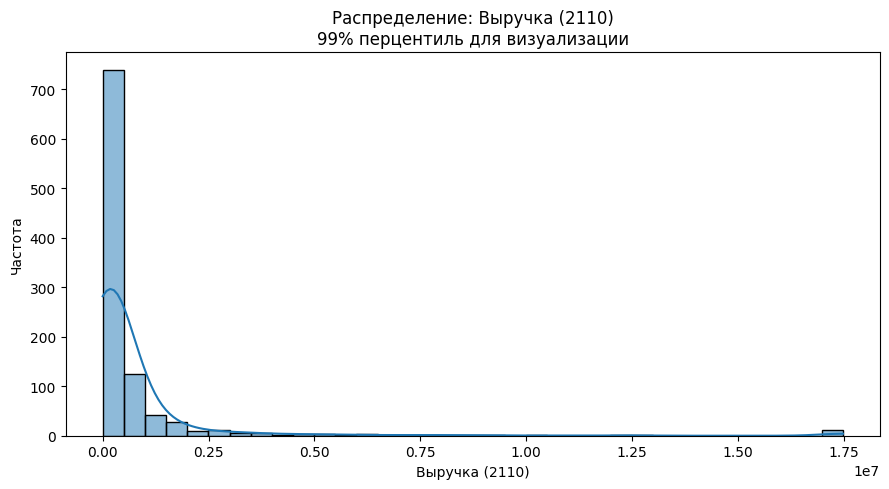

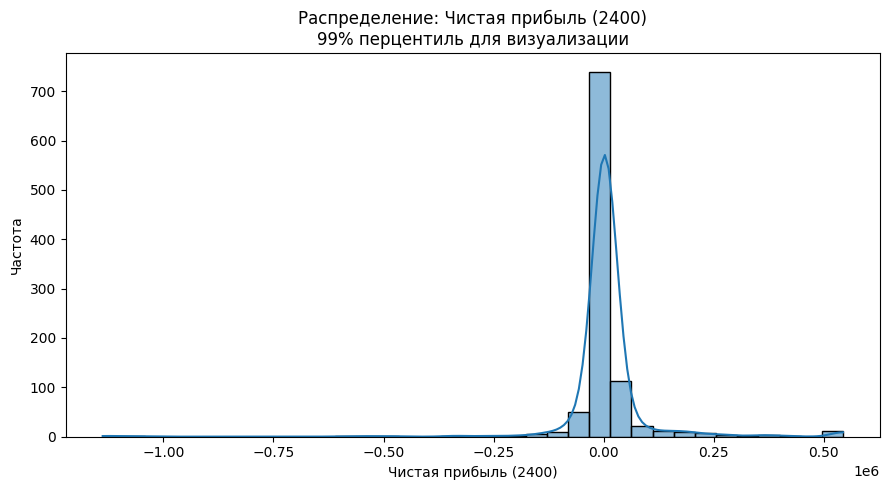

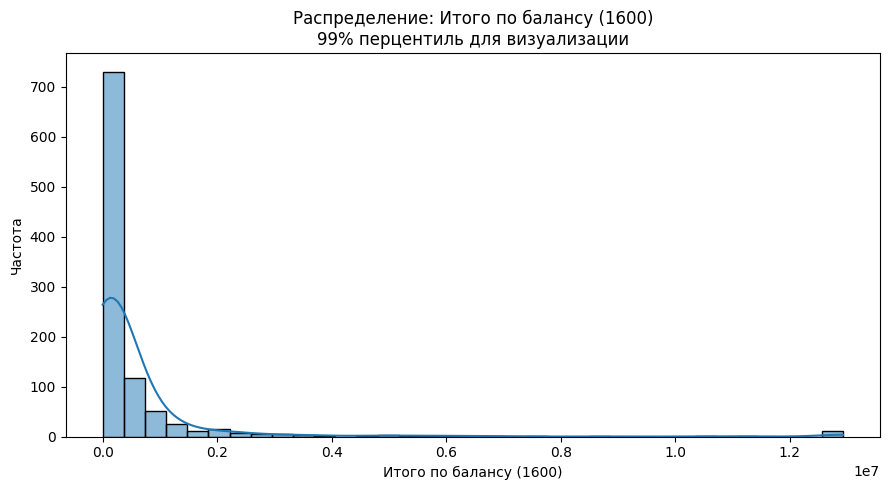

In [6]:
hist_cols = ["line_2110", "line_2400", "line_1600"]
hist_results=[]
for column in hist_cols:
  x = df[column].dropna()
  q1, q3 = x.quantile([0.25, 0.75])
  iqr = q3 - q1
  lower = q1 - 1.5 * iqr
  upper = q3 + 1.5 * iqr
  outliers = x[(x < lower) | (x > upper)]

  # Financial variables are strongly right-skewed. Use a clipped view for
  # readability while also reporting the actual IQR outlier count.
  cap = x.quantile(0.99)
  plot_x = x.clip(upper=cap)

  fig, ax = plt.subplots(figsize=(9, 5))
  sns.histplot(plot_x, bins=35, kde=True, ax=ax)
  ax.set_title(f"Распределение: {LABELS[column]}\n99% перцентиль для визуализации")
  ax.set_xlabel(LABELS[column])
  ax.set_ylabel("Частота")
  fig.tight_layout()
  fig.savefig(OUT / f"hist_{column}.png", dpi=160)
  plt.show()
  plt.close(fig)
  hist_results.append({
        "column": column,
        "q1": q1,
        "median": x.median(),
        "q3": q3,
        "iqr": iqr,
        "lower": lower,
        "upper": upper,
        "outliers": len(outliers),
        "outlier_pct": len(outliers) / len(x) * 100,
        "min": x.min(),
        "max": x.max(),
  })
  pd.DataFrame(hist_results).T.to_csv(OUT / "histogram_outlier_report.csv")

По гистограммам видно, что большая часть значений укладывается в нормальное распределение, однако часть значений выглядит аномально высокими

Этап 4. Построение матрицы корреляции

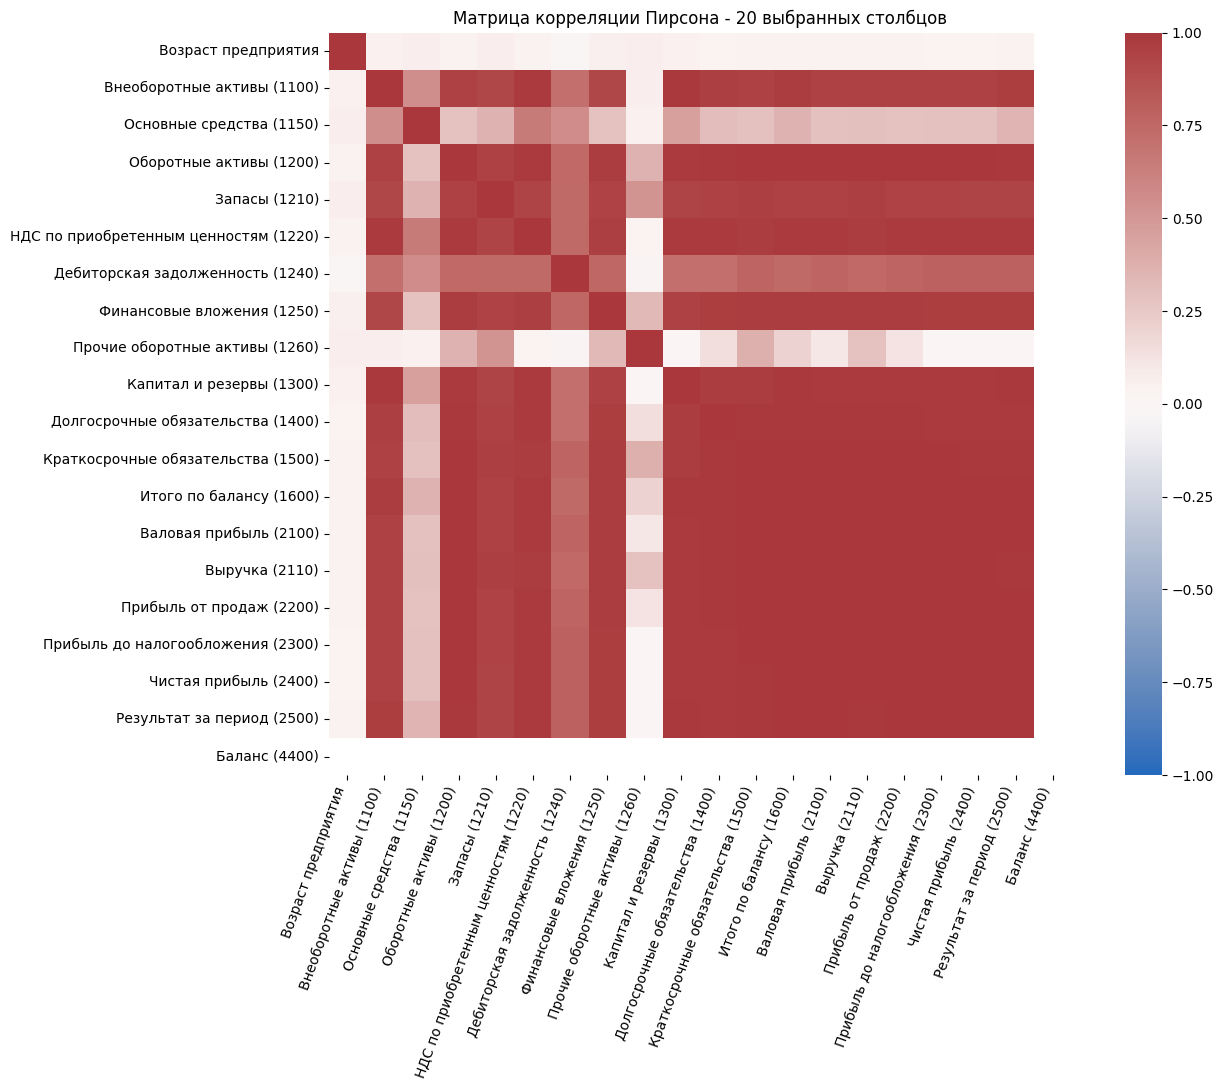


=== НАИБОЛЬШИЕ КОРРЕЛЯЦИИ ===
 column_a  column_b  pearson_r    abs_r
line_2300 line_2400   0.999948 0.999948
line_2200 line_2300   0.999313 0.999313
line_2100 line_2200   0.999140 0.999140
line_2200 line_2400   0.999068 0.999068
line_2100 line_2300   0.998190 0.998190
line_1200 line_2100   0.997997 0.997997
line_1200 line_2110   0.997847 0.997847
line_2100 line_2400   0.997787 0.997787
line_1200 line_2200   0.997722 0.997722
line_2400 line_2500   0.997529 0.997529
line_2300 line_2500   0.997379 0.997379
line_2100 line_2110   0.996779 0.996779
line_1200 line_1500   0.996145 0.996145
line_1200 line_1600   0.996045 0.996045
line_1200 line_2300   0.995892 0.995892


In [11]:
corr = df.corr(method="pearson", min_periods=30)
corr.to_csv(OUT / "correlation_matrix.csv")

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    corr,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
    xticklabels=[LABELS[c] for c in corr.columns],
    yticklabels=[LABELS[c] for c in corr.index],
)
ax.set_title("Матрица корреляции Пирсона - 20 выбранных столбцов")
plt.xticks(rotation=70, ha="right")
plt.yticks(rotation=0)
fig.tight_layout()
fig.savefig(OUT / "correlation_matrix.png", dpi=180)
plt.show()
plt.close(fig)

pairs = []
for i, a in enumerate(corr.columns):
    for b in corr.columns[i + 1:]:
        r = corr.loc[a, b]
        if pd.notna(r):
            pairs.append((a, b, r, abs(r)))
pairs = sorted(pairs, key=lambda z: z[3], reverse=True)
top = pd.DataFrame(pairs, columns=["column_a", "column_b", "pearson_r", "abs_r"]).head(15)
top.to_csv(OUT / "top_correlations.csv", index=False)
print("\n=== НАИБОЛЬШИЕ КОРРЕЛЯЦИИ ===")
print(top.to_string(index=False))

Практически все финансовые показатели прямо коррелируют между собой, что, казалось бы, можно объяснить их экономической взаимосвязью и тем, что некоторые показатели напрямую по формулам вычисляются на основе других.

Но на гистограммах мы видели, что часть данных - аномально большие выбросы. Проверим гипотезу о выбросах, построим матрицу рассеивания для не отфильтрованных данных и отфильтрованных по 99-му перцентилю для двух показателей - Выручки и Чистой прибыли

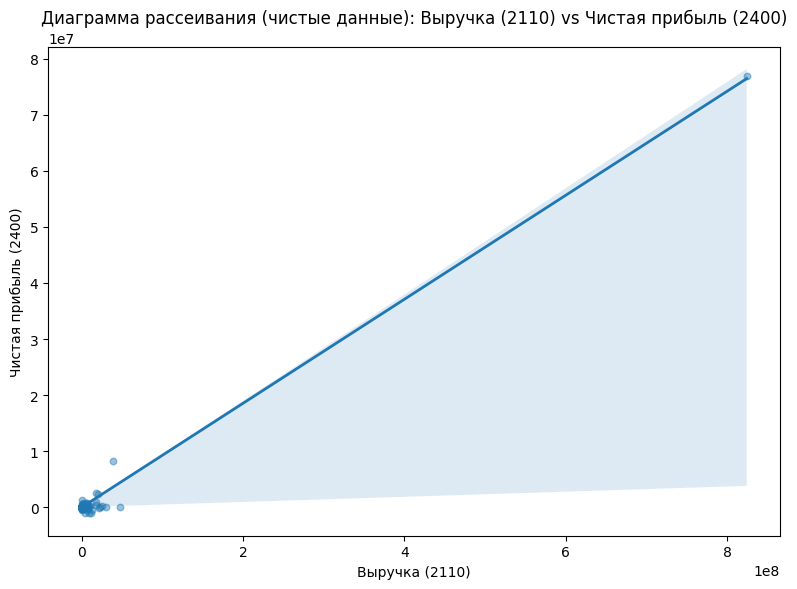

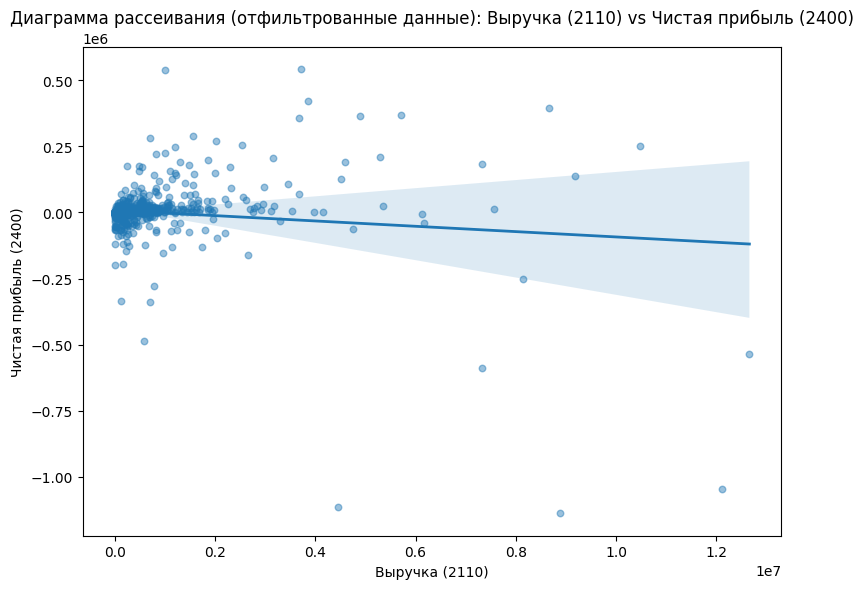

In [14]:
a="line_2110"
b="line_2400"
data = df[[a, b]].dropna()
#Чистые данные
xa = data[a]
xb = data[b]
plot = data[(data[a] <= xa) & (data[b] <= xb)]
fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(data=plot, x=a, y=b, scatter_kws={"alpha": 0.45, "s": 22}, line_kws={"linewidth": 2}, ax=ax)
ax.set_xlabel(LABELS[a])
ax.set_ylabel(LABELS[b])
ax.set_title(f"Диаграмма рассеивания (чистые данные): {LABELS[a]} vs {LABELS[b]}")
fig.tight_layout()
fig.savefig(OUT / "scatter_top_correlation_unfiltered.png", dpi=180)
plt.show()
plt.close(fig)
#Отфильтрованные по 99-му перцентилю данные
xa = data[a].quantile(0.99)
xb = data[b].quantile(0.99)
plot = data[(data[a] <= xa) & (data[b] <= xb)]
fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(data=plot, x=a, y=b, scatter_kws={"alpha": 0.45, "s": 22}, line_kws={"linewidth": 2}, ax=ax)
ax.set_xlabel(LABELS[a])
ax.set_ylabel(LABELS[b])
ax.set_title(f"Диаграмма рассеивания (отфильтрованные данные): {LABELS[a]} vs {LABELS[b]}")
fig.tight_layout()
fig.savefig(OUT / "scatter_top_correlation_filtered.png", dpi=180)
plt.show()
plt.close(fig)

Теперь становится интереснее. Здесь мы можем сделать вывод, что выбросы очень сильно влияют на матрицу корреляции. Построим матрицу корреляции попарно, удалив аномальные выбросы

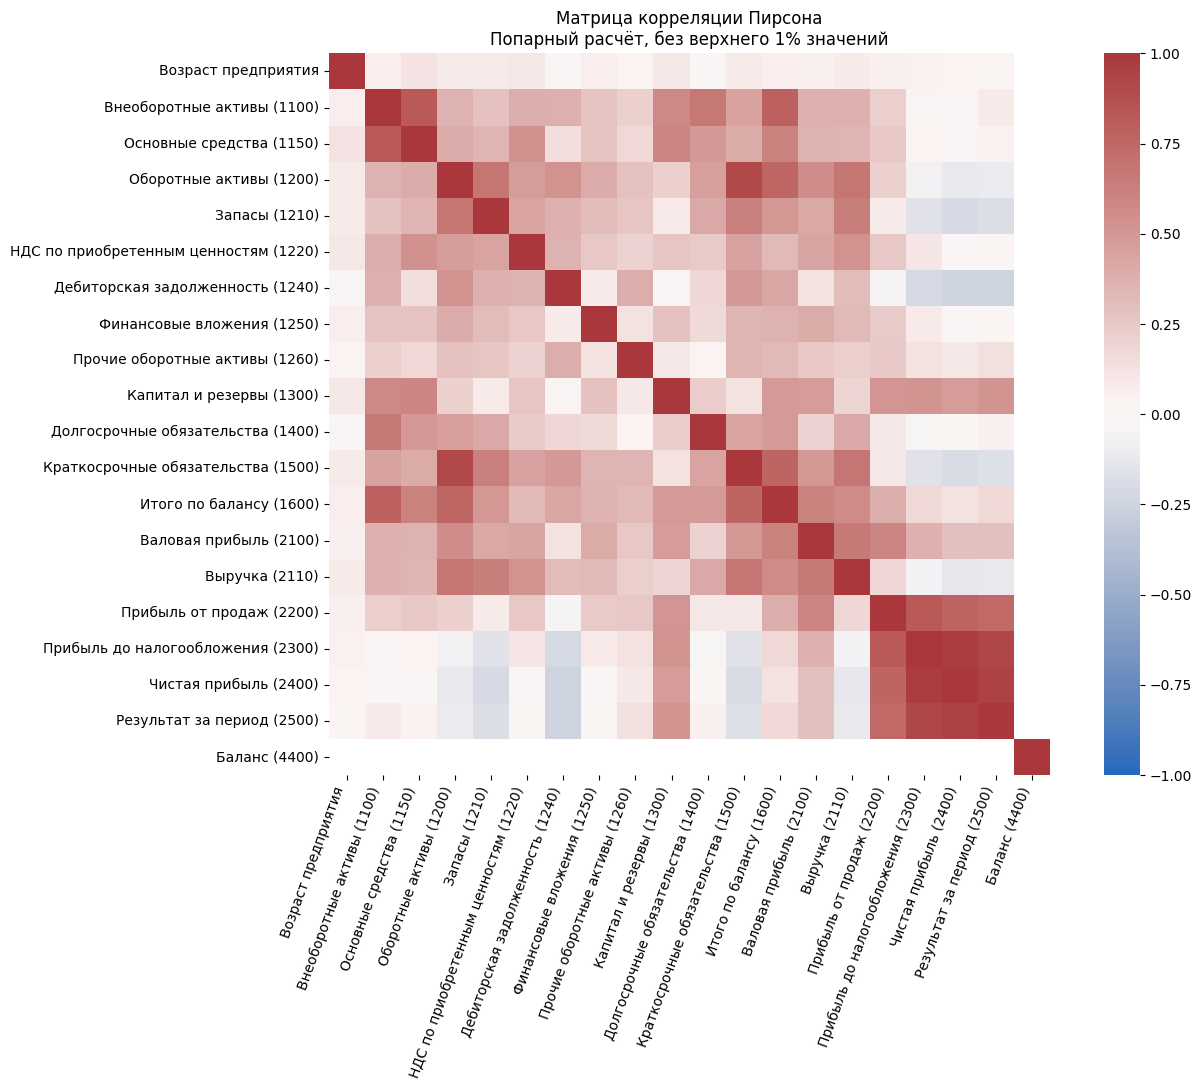


=== НАИБОЛЬШИЕ КОРРЕЛЯЦИИ ===
 column_a  column_b  pearson_r    abs_r
line_2300 line_2400   0.975150 0.975150
line_2400 line_2500   0.949888 0.949888
line_2300 line_2500   0.928744 0.928744
line_1200 line_1500   0.910913 0.910913
line_2200 line_2300   0.826711 0.826711
line_1100 line_1150   0.824065 0.824065
line_1100 line_1600   0.784448 0.784448
line_2200 line_2400   0.772329 0.772329
line_1500 line_1600   0.765661 0.765661
line_1200 line_1600   0.760845 0.760845
line_2200 line_2500   0.749568 0.749568
line_1200 line_1210   0.686838 0.686838
line_1200 line_2110   0.684209 0.684209
line_1500 line_2110   0.678518 0.678518
line_1100 line_1400   0.671309 0.671309


In [16]:
corr = pd.DataFrame(
    np.eye(len(df.columns)),
    index=df.columns,
    columns=df.columns
)

for i, a in enumerate(df.columns):
    for j, b in enumerate(df.columns):

        if i >= j:
            continue

        data = df[[a, b]].dropna()

        if len(data) < 30:
            r = np.nan
        else:
            # Удаляем верхний 1 процент
            q99_a = data[a].quantile(0.99)
            q99_b = data[b].quantile(0.99)

            data = data[
                (data[a] <= q99_a) &
                (data[b] <= q99_b)
            ]

            # Вычисляем корреляцию Пирсона
            if len(data) >= 30:
                r = data[a].corr(data[b])
            else:
                r = np.nan

        corr.loc[a, b] = r
        corr.loc[b, a] = r


# Сохраняем матрицу корреляции
corr.to_csv(OUT / "correlation_matrix_filtered.csv")


# Plot heatmap
fig, ax = plt.subplots(figsize=(14, 11))

sns.heatmap(
    corr,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
    xticklabels=[LABELS[c] for c in corr.columns],
    yticklabels=[LABELS[c] for c in corr.index],
)

ax.set_title(
    "Матрица корреляции Пирсона\n"
    "Попарный расчёт, без верхнего 1% значений"
)

plt.xticks(rotation=70, ha="right")
plt.yticks(rotation=0)

fig.tight_layout()
fig.savefig(
    OUT / "correlation_matrix.png",
    dpi=180
)

plt.show()
plt.close(fig)

pairs = []
for i, a in enumerate(corr.columns):
    for b in corr.columns[i + 1:]:
        r = corr.loc[a, b]
        if pd.notna(r):
            pairs.append((a, b, r, abs(r)))
pairs = sorted(pairs, key=lambda z: z[3], reverse=True)
top = pd.DataFrame(pairs, columns=["column_a", "column_b", "pearson_r", "abs_r"]).head(15)
top.to_csv(OUT / "top_correlations_filtered.csv", index=False)
print("\n=== НАИБОЛЬШИЕ КОРРЕЛЯЦИИ ===")
print(top.to_string(index=False))

Вот теперь матрица имеет уже человеческий вид, и сильная корреляция в правой нижней части объясняется прямым вычислением показателей прибыли друг от друга.

Главный вывод по работе - аномальные значения надо исключать из анализа, чтобы получить пригодный результат)